# Методы aeon на PowerCons

Сравним расстояния, случайные свертки, признаки и нейросети на PowerCons, классификация использует все 144 точки, регрессия прогнозирует среднее следующих 24 точек по первым 120

Для каждого семейства обучим минимум три классификатора и три регрессора, параметры выбираем на одних и тех же 144 обучающих и 36 валидационных рядах, после выбора переобучаем на 180 TRAIN и оцениваем на 180 TEST

Основная библиотека — aeon, дополнительные реализации указаны рядом с экспериментами

## Загрузка и анализ

[Официальный PowerCons](https://www.timeseriesclassification.com/description.php?Dataset=PowerCons): класс 1 соответствует теплому сезону, класс 2 — холодному, точка означает десятиминутное измерение потребления

In [1]:
import os
os.environ.setdefault('NUMBA_NUM_THREADS', '4')
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeClassifier, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier, ExtraTreesRegressor
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.grid': True, 'grid.alpha': .2})
ROOT = Path.cwd()
DATA = ROOT / 'data' / 'PowerCons'
DATA.mkdir(parents=True, exist_ok=True)
required = [f'PowerCons_{s}.txt' for s in ('TRAIN', 'TEST')]
if not all((DATA / f).exists() for f in required):
    url = 'https://www.timeseriesclassification.com/aeon-toolkit/PowerCons.zip'
    with urlopen(url, timeout=90) as response:
        archive = ZipFile(BytesIO(response.read()))
    for name in required:
        member = next(m for m in archive.namelist() if Path(m).name == name)
        (DATA / name).write_bytes(archive.read(member))
def load_split(name):
    a = np.loadtxt(DATA / f'PowerCons_{name}.txt')
    x, y = a[:, 1:].astype(np.float64), a[:, 0].astype(int)
    assert x.shape == (180, 144) and np.isfinite(x).all()
    assert set(y) == {1, 2}
    return x, y
X_train, y_train = load_split('TRAIN')
X_test, y_test = load_split('TEST')
fit_idx, val_idx = train_test_split(np.arange(180), test_size=.2,
    random_state=SEED, stratify=y_train)
display(pd.DataFrame({'TRAIN': pd.Series(y_train).value_counts(),
                      'TEST': pd.Series(y_test).value_counts()}).rename_axis('Класс'))
print('TRAIN:', X_train.shape, 'TEST:', X_test.shape,
      'fit / validation:', len(fit_idx), len(val_idx))

,TRAIN,TEST
Класс,,
1,90,90
2,90,90


TRAIN: (180, 144) TEST: (180, 144) fit / validation: 144 36


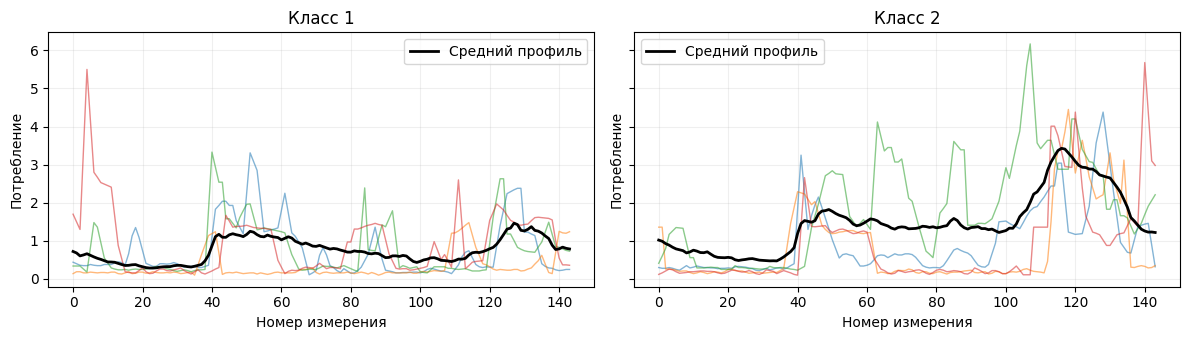

,Среднее,Стандартное отклонение,Минимум,Максимум
count,180.000,180.000,180.00,180.000
mean,1.114,0.909,0.20,4.196
std,0.517,0.302,0.09,1.447
min,0.320,0.260,0.04,1.380
25%,0.739,0.716,0.13,3.245
50%,0.998,0.902,0.22,4.305
75%,1.406,1.098,0.23,5.102
max,2.771,1.576,0.81,7.800


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for cls, ax in zip((1, 2), axes):
    rows = X_train[y_train == cls]
    for row in rows[:4]:
        ax.plot(row, alpha=.55, linewidth=1)
    ax.plot(rows.mean(axis=0), color='black', linewidth=2, label='Средний профиль')
    ax.set(title=f'Класс {cls}', xlabel='Номер измерения', ylabel='Потребление')
    ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Среднее': X_train.mean(1), 'Стандартное отклонение': X_train.std(1),
                      'Минимум': X_train.min(1), 'Максимум': X_train.max(1)}).describe().round(3))

## Регрессионная цель

Если полный ряд стандартизирован к нулевому среднему, среднее его хвоста равно минус пяти средним префикса, проверим это до обучения

У PowerCons средние рядов и масштабы различаются, поэтому эта тождественная связь не выполняется и оставляем среднее последних 24 точек в качестве цели, скрытый участок не участвует в нормализации входа

Средние TRAIN: 0.3199 ... 2.7713
Стандартные отклонения: 0.2599 ... 1.5760
Максимальная невязка предполагаемой связи y=-5*mean(prefix): 16.6279


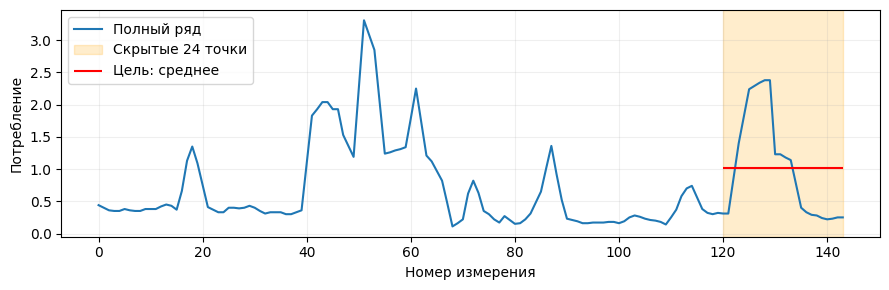

In [3]:
# Проверяем только TRAIN перед выбором регрессионной постановки
means, stds = X_train.mean(1), X_train.std(1)
identity_error = np.max(np.abs(X_train[:, 120:].mean(1) + 5*X_train[:, :120].mean(1)))
full_z = np.max(np.abs(means)) < 1e-6 and np.max(np.abs(stds-1)) < 1e-6
assert not full_z, 'Для z-нормализованных рядов нужно изменить цель на последнее значение'
print(f'Средние TRAIN: {means.min():.4f} ... {means.max():.4f}')
print(f'Стандартные отклонения: {stds.min():.4f} ... {stds.max():.4f}')
print(f'Максимальная невязка предполагаемой связи y=-5*mean(prefix): {identity_error:.4f}')
Xr_train, Xr_test = X_train[:, :120].copy(), X_test[:, :120].copy()
yr_train, yr_test = X_train[:, 120:].mean(1), X_test[:, 120:].mean(1)
assert Xr_train.shape == Xr_test.shape == (180, 120)
assert np.isfinite(yr_train).all() and np.isfinite(yr_test).all()
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(X_train[0], label='Полный ряд')
ax.axvspan(120, 143, alpha=.2, color='orange', label='Скрытые 24 точки')
ax.hlines(yr_train[0], 120, 143, color='red', label='Цель: среднее')
ax.set(xlabel='Номер измерения', ylabel='Потребление')
ax.legend()
plt.tight_layout()
plt.show()

## Подготовка экспериментов

Масштабируем вход одним средним и стандартным отклонением, рассчитанными только по обучаемой части, это сохраняет различия уровней между рядами

Для линейных моделей дополнительно масштабируем извлеченные признаки, ни один трансформер не обучается на TEST

In [4]:
%pip install aeon
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import FunctionTransformer
from aeon.transformations.collection.convolution_based import Rocket, MiniRocket
from aeon.transformations.collection.feature_based import SevenNumberSummary

class GlobalSeriesScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.mean_ = float(np.mean(X))
        self.scale_ = max(float(np.std(X)), 1e-8)
        return self
    def transform(self, X):
        return (np.asarray(X)-self.mean_)/self.scale_

class HydraNumpy(BaseEstimator, TransformerMixin):
    # Одномерный перенос алгоритма HYDRA: random kernels, dilations, competition
    # Источник алгоритма: aeon 1.3, _hydra.py, оригинал Angus Dempster
    # Это NumPy-реализация, не класс HydraTransformer из aeon
    def __init__(self, n_kernels=8, n_groups=16, random_state=42):
        self.n_kernels, self.n_groups, self.random_state = n_kernels, n_groups, random_state
    def fit(self, X, y=None):
        assert X.shape[1] == 1 and self.n_groups % 2 == 0
        self.dilations_ = 2**np.arange(int(np.log2((X.shape[2]-1)/8))+1)
        rng = np.random.default_rng(self.random_state)
        w = rng.normal(size=(len(self.dilations_), 2, self.n_groups//2, self.n_kernels, 9))
        w -= w.mean(-1, keepdims=True)
        self.kernels_ = w / np.abs(w).sum(-1, keepdims=True)
        return self
    def transform(self, X):
        x = np.asarray(X)[:, 0, :]
        blocks = []
        for di, dilation in enumerate(self.dilations_):
            for branch, signal in enumerate((x, np.diff(x, axis=1))):
                pad = int(4*dilation)
                padded = np.pad(signal, ((0,0),(pad,pad)))
                # Окна с расширением сохраняют исходный порядок измерений
                windows = np.stack([padded[:,j*dilation:j*dilation+signal.shape[1]] for j in range(9)], axis=-1)
                responses = np.einsum('ntw,gkw->ngkt', windows, self.kernels_[di,branch], optimize=True)
                winners, losers = responses.argmax(2), responses.argmin(2)
                maximum = responses.max(2)
                weighted_wins = np.stack([(maximum*(winners == k)).sum(-1) for k in range(self.n_kernels)],axis=-1)
                min_counts = np.stack([(losers == k).sum(-1) for k in range(self.n_kernels)],axis=-1)
                blocks.extend([weighted_wins.reshape(len(x),-1), min_counts.reshape(len(x),-1)])
        return np.concatenate(blocks, axis=1)

def dynamic_features(X):
    a = np.asarray(X).reshape(len(X), -1)
    d = np.diff(a, axis=1)
    segments = np.array_split(a, 6, axis=1)
    spectrum = np.abs(np.fft.rfft(a-a.mean(1,keepdims=True), axis=1))[:,1:9]
    return np.column_stack([a.mean(1), a.std(1), a.min(1), a.max(1),
        np.median(a,axis=1), d.std(1), a[:,-1], a[:,-1]-a[:,0],
        *[s.mean(1) for s in segments], spectrum])

def table_model(transform, estimator):
    return make_pipeline(GlobalSeriesScaler(), transform, StandardScaler(), estimator)

def scores(task, y, pred):
    pred = np.asarray(pred).reshape(-1)
    assert len(pred) == len(y) and np.isfinite(pred).all()
    if task == 'classification':
        return {'Accuracy':accuracy_score(y,pred),'Macro F1':f1_score(y,pred,average='macro')}
    return {'MAE':mean_absolute_error(y,pred), 'RMSE':np.sqrt(mean_squared_error(y,pred)), 'R2':r2_score(y,pred)}

rows, validation_rows, predictions, histories = [], [], {}, {}
tasks = {
    'classification':(X_train[:,None,:], y_train, X_test[:,None,:], y_test),
    'regression':(Xr_train[:,None,:], yr_train, Xr_test[:,None,:], yr_test)}

def evaluate(name, family, task, candidates, library):
    xt, yt, xe, ye = tasks[task]
    choices = []
    start = time.perf_counter()
    for label, factory in candidates:
        model = factory()
        model.fit(xt[fit_idx], yt[fit_idx])
        metrics = scores(task,yt[val_idx],model.predict(xt[val_idx]))
        validation_rows.append({'Family':family,'Task':task,'Model':name,'Config':label,**metrics})
        objective = metrics['Macro F1'] if task == 'classification' else -metrics['RMSE']
        choices.append((objective, label, factory, metrics))
    _, label, factory, val = max(choices, key=lambda t:t[0])
    model = factory()
    model.fit(xt,yt)
    pred = np.asarray(model.predict(xe)).reshape(-1)
    predictions[(task,name)] = pred
    rows.append({'Family':family,'Task':task,'Model':name,'Library':library,'Config':label,
        'Validation score':val['Macro F1'] if task=='classification' else val['RMSE'],
        **scores(task,ye,pred),'Seconds':time.perf_counter()-start})
    print(task, name, scores(task,ye,pred), flush=True)

def show_family(family):
    frame = pd.DataFrame(rows)
    for task in tasks:
        cols = ['Model','Config','Accuracy','Macro F1'] if task=='classification' else ['Model','Config','MAE','RMSE','R2']
        display(frame[(frame.Family==family)&(frame.Task==task)][cols].round(4))

def run_convolutions():
    for name, transform_factory, lib in [
        ('ROCKET',lambda:Rocket(n_kernels=1000,random_state=SEED,n_jobs=4),'aeon'),
        ('MiniROCKET',lambda:MiniRocket(n_kernels=1008,random_state=SEED,n_jobs=4),'aeon'),
        ('HYDRA NumPy',lambda:HydraNumpy(random_state=SEED),'NumPy, алгоритм HYDRA')]:
        for task in tasks:
            def factory(alpha, task=task, tfactory=transform_factory):
                estimator = RidgeClassifier(alpha=alpha) if task=='classification' else Ridge(alpha=alpha)
                return table_model(tfactory(),estimator)
            evaluate(name,'Convolution',task,[(f'alpha={a}',lambda a=a:factory(a)) for a in (.1,10.)],lib)
    show_family('Convolution')

In [ ]:
LAB_NAME = 'lab14'

## Расстояния

Сравним евклидово расстояние, DTW с окном 10% и MSM, евклидово расстояние сопоставляет одинаковые моменты, DTW разрешает локальные сдвиги, MSM допускает операции перемещения, разделения и слияния

Для каждого расстояния выбираем 1 или 3 соседа по валидации, классификация голосует по меткам, регрессия усредняет ответы соседей

In [5]:
from aeon.classification.distance_based import KNeighborsTimeSeriesClassifier
from aeon.regression.distance_based import KNeighborsTimeSeriesRegressor
for metric, params in [('euclidean',{}),('dtw',{'window':.1}),('msm',{'c':1.})]:
    for task in tasks:
        cls = KNeighborsTimeSeriesClassifier if task=='classification' else KNeighborsTimeSeriesRegressor
        def factory(k, cls=cls, metric=metric, params=params):
            return make_pipeline(GlobalSeriesScaler(),cls(distance=metric,distance_params=params,n_neighbors=k,n_jobs=4))
        evaluate(f'KNN {metric}','Distance',task,[(f'k={k}',lambda k=k:factory(k)) for k in (1,3)],'aeon')
show_family('Distance')

/usr/local/lib/python3.13/dist-packages/aeon/distances/pointwise/_euclidean.py:173: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  distances[i, j] = euclidean_distance(x[i], y[j])


classification KNN euclidean {'Accuracy': 0.9666666666666667, 'Macro F1': 0.9666625509322139}
regression KNN euclidean {'MAE': 0.3540115740740741, 'RMSE': np.float64(0.6136538443635472), 'R2': 0.47103369803116724}
classification KNN dtw {'Accuracy': 0.9388888888888889, 'Macro F1': 0.9388719088635733}
regression KNN dtw {'MAE': 0.4989413580246913, 'RMSE': np.float64(0.6673855452484087), 'R2': 0.37434534567964295}
classification KNN msm {'Accuracy': 0.9555555555555556, 'Macro F1': 0.9555061179087876}
regression KNN msm {'MAE': 0.5139413580246913, 'RMSE': np.float64(0.6795362966049975), 'R2': 0.3513559996689454}


,Model,Config,Accuracy,Macro F1
0,KNN euclidean,k=3,0.9667,0.9667
2,KNN dtw,k=1,0.9389,0.9389
4,KNN msm,k=3,0.9556,0.9555


,Model,Config,MAE,RMSE,R2
1,KNN euclidean,k=1,0.3540,0.6137,0.4710
3,KNN dtw,k=3,0.4989,0.6674,0.3743
5,KNN msm,k=3,0.5139,0.6795,0.3514


## Случайные свертки

ROCKET и MiniROCKET взяты из aeon, для классификации используем RidgeClassifier, для регрессии — Ridge, коэффициент регуляризации выбираем из 0,1 и 10 по validation

HYDRA реализован на NumPy по [одномерному алгоритму aeon 1.3](https://github.com/aeon-toolkit/aeon/blob/v1.3.0/aeon/transformations/collection/convolution_based/_hydra.py): ядра длины 9 с нулевым средним и единичной L1-нормой, степени двойки для dilation, исходный сигнал и его разности, взвешенные победы максимума и счетчики минимума

Это отдельный перенос алгоритма, а не вызов HydraTransformer, его необходимость связана с зависимостью aeon HYDRA от PyTorch, настройка PyTorch по условию отложена до финального проекта

Ограничим ROCKET тысячей ядер, MiniROCKET — 1008 ядрами, HYDRA — 16 группами, чтобы сравнение на небольшом наборе оставалось быстрым

In [ ]:
run_convolutions()

classification ROCKET {'Accuracy': 0.9388888888888889, 'Macro F1': 0.9388416988416989}


regression ROCKET {'MAE': 0.37526211351377, 'RMSE': 0.5972545969314218, 'R2': 0.4989280523230255}


classification MiniROCKET {'Accuracy': 1.0, 'Macro F1': 1.0}


regression MiniROCKET {'MAE': 0.33614794109044255, 'RMSE': 0.5253765495871721, 'R2': 0.6122762046316755}


classification HYDRA NumPy {'Accuracy': 0.9666666666666667, 'Macro F1': 0.9666625509322139}


regression HYDRA NumPy {'MAE': 0.3510515416994866, 'RMSE': 0.5496849962726921, 'R2': 0.5755672832858816}


,Model,Config,Accuracy,Macro F1
6,ROCKET,alpha=0.1,0.9389,0.9388
8,MiniROCKET,alpha=0.1,1.0000,1.0000
10,HYDRA NumPy,alpha=0.1,0.9667,0.9667


,Model,Config,MAE,RMSE,R2
7,ROCKET,alpha=10.0,0.3753,0.5973,0.4989
9,MiniROCKET,alpha=10.0,0.3361,0.5254,0.6123
11,HYDRA NumPy,alpha=10.0,0.3511,0.5497,0.5756


## Признаки

Используем SevenNumberSummary из aeon с линейной моделью, статистику и динамику с Random Forest, те же расширенные признаки с Extra Trees

В расширенный набор входят уровни по шести последовательным интервалам, последние доступные значения, характеристики разностей и первые восемь ненулевых амплитуд спектра, порядок точек сохраняется

In [ ]:
for task in tasks:
    linear = RidgeClassifier if task=='classification' else Ridge
    forest = RandomForestClassifier if task=='classification' else RandomForestRegressor
    extra = ExtraTreesClassifier if task=='classification' else ExtraTreesRegressor
    definitions = [
        ('Summary + Ridge',lambda a:table_model(SevenNumberSummary(),linear(alpha=a)),(.1,10.)),
        ('Dynamics + RF',lambda depth:table_model(FunctionTransformer(dynamic_features),forest(n_estimators=100,max_depth=depth,random_state=SEED,n_jobs=4)),(4,None)),
        ('Dynamics + ExtraTrees',lambda depth:table_model(FunctionTransformer(dynamic_features),extra(n_estimators=100,max_depth=depth,random_state=SEED,n_jobs=4)),(4,None))]
    for name,factory,options in definitions:
        evaluate(name,'Feature',task,[(str(p),lambda p=p,factory=factory:factory(p)) for p in options],
            'aeon + sklearn' if name.startswith('Summary') else 'NumPy + sklearn')
show_family('Feature')

classification Summary + Ridge {'Accuracy': 0.8944444444444445, 'Macro F1': 0.8944151153098083}


classification Dynamics + RF {'Accuracy': 0.9888888888888889, 'Macro F1': 0.9888888888888889}


classification Dynamics + ExtraTrees {'Accuracy': 0.9777777777777777, 'Macro F1': 0.9777750339548092}


regression Summary + Ridge {'MAE': 0.5803201894893276, 'RMSE': 0.723914649195682, 'R2': 0.26386779565233087}


regression Dynamics + RF {'MAE': 0.37376578703703683, 'RMSE': 0.5293195177174299, 'R2': 0.606434606443897}


regression Dynamics + ExtraTrees {'MAE': 0.31876055555555616, 'RMSE': 0.5145651321717335, 'R2': 0.628069498197236}


,Model,Config,Accuracy,Macro F1
12,Summary + Ridge,0.1,0.8944,0.8944
13,Dynamics + RF,4,0.9889,0.9889
14,Dynamics + ExtraTrees,None,0.9778,0.9778


,Model,Config,MAE,RMSE,R2
15,Summary + Ridge,10.0,0.5803,0.7239,0.2639
16,Dynamics + RF,None,0.3738,0.5293,0.6064
17,Dynamics + ExtraTrees,None,0.3188,0.5146,0.6281


## Нейросети

Используем совместимые реализации TensorFlow/Keras: MLP с двумя скрытыми слоями, FCN с тремя свертками и ResNet с двумя остаточными блоками, это разные архитектуры, а не три размера одной сети

Обучаем не более 60 эпох с early stopping по validation loss и patience 8, сохраняем выбранное число эпох и затем обучаем сеть заново на полном TRAIN, регрессионную цель масштабируем только по обучающим ответам

In [7]:
import tensorflow as tf
from tensorflow import keras
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

def make_network(length, architecture, task):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input((length,1))
    if architecture == 'MLP':
        z = keras.layers.Flatten()(inputs)
        z = keras.layers.Dense(64,activation='relu')(z)
        z = keras.layers.Dense(32,activation='relu')(z)
    elif architecture == 'FCN':
        z = inputs
        for filters, kernel in [(16,7),(32,5),(32,3)]:
            z = keras.layers.Conv1D(filters,kernel,padding='same',activation='relu')(z)
        z = keras.layers.GlobalAveragePooling1D()(z)
    elif architecture == 'ResNet':
        z = keras.layers.Conv1D(16,1,padding='same')(inputs)
        for _ in range(2):
            shortcut = z
            z = keras.layers.Conv1D(16,5,padding='same',activation='relu')(z)
            z = keras.layers.Conv1D(16,3,padding='same')(z)
            z = keras.layers.Activation('relu')(keras.layers.Add()([z,shortcut]))
        z = keras.layers.GlobalAveragePooling1D()(z)
    else:
        raise ValueError(architecture)
    outputs = keras.layers.Dense(2,activation='softmax')(z) if task=='classification' else keras.layers.Dense(1)(z)
    model = keras.Model(inputs,outputs)
    model.compile(optimizer=keras.optimizers.Adam(.003),
        loss='sparse_categorical_crossentropy' if task=='classification' else 'mse')
    return model

def dataset(x,y,shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x,y))
    if shuffle:
        ds = ds.shuffle(len(x),seed=SEED,reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return ds.batch(32).with_options(options)

def evaluate_network(architecture, task):
    xt, yt, xe, ye = tasks[task]
    xt, xe = xt.transpose(0,2,1), xe.transpose(0,2,1)
    start = time.perf_counter()
    scaler = GlobalSeriesScaler().fit(xt[fit_idx])
    if task=='classification':
        target_mean, target_scale = 0.,1.
        yn = yt-1
    else:
        target_mean, target_scale = yt[fit_idx].mean(), max(yt[fit_idx].std(),1e-8)
        yn = (yt-target_mean)/target_scale
    model = make_network(xt.shape[1],architecture,task)
    history = model.fit(dataset(scaler.transform(xt[fit_idx]),yn[fit_idx],True),
        validation_data=dataset(scaler.transform(xt[val_idx]),yn[val_idx]),
        epochs=60,verbose=0,callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=8,restore_best_weights=True)])
    best_epoch = int(np.argmin(history.history['val_loss']))+1
    raw = model(scaler.transform(xt[val_idx]),training=False).numpy()
    pval = raw.argmax(1)+1 if task=='classification' else raw.ravel()*target_scale+target_mean
    val = scores(task,yt[val_idx],pval)
    name = f'{architecture} Keras'
    histories[(task,name)] = history.history
    validation_rows.append({'Family':'Deep Learning','Task':task,'Model':name,'Config':f'epochs={best_epoch}',**val})
    # Число эпох выбрано по validation, затем обучаем заново на полном TRAIN
    scaler = GlobalSeriesScaler().fit(xt)
    if task=='regression':
        target_mean, target_scale = yt.mean(), max(yt.std(),1e-8)
        yn = (yt-target_mean)/target_scale
    model = make_network(xt.shape[1],architecture,task)
    model.fit(dataset(scaler.transform(xt),yn,True),epochs=best_epoch,verbose=0)
    raw = model(scaler.transform(xe),training=False).numpy()
    pred = raw.argmax(1)+1 if task=='classification' else raw.ravel()*target_scale+target_mean
    predictions[(task,name)] = pred
    rows.append({'Family':'Deep Learning','Task':task,'Model':name,'Library':'TensorFlow/Keras',
        'Config':f'epochs={best_epoch}', 'Validation score':val['Macro F1'] if task=='classification' else val['RMSE'],
        **scores(task,ye,pred),'Seconds':time.perf_counter()-start})
    print(task,name,scores(task,ye,pred),flush=True)

In [8]:
for architecture in ['MLP','FCN','ResNet']:
    for task in tasks:
        evaluate_network(architecture,task)
show_family('Deep Learning')

classification MLP Keras {'Accuracy': 0.9888888888888889, 'Macro F1': 0.9888888888888889}
regression MLP Keras {'MAE': 0.5646706897192528, 'RMSE': np.float64(0.7328718373274404), 'R2': 0.2455383771360583}
classification FCN Keras {'Accuracy': 0.8777777777777778, 'Macro F1': 0.8777173913043479}
regression FCN Keras {'MAE': 0.5478698126821059, 'RMSE': np.float64(0.6976092111187493), 'R2': 0.31639457581895025}
classification ResNet Keras {'Accuracy': 0.8833333333333333, 'Macro F1': 0.8828960004956783}
regression ResNet Keras {'MAE': 0.6112815204745133, 'RMSE': np.float64(0.76289203646421), 'R2': 0.18246331369969893}


,Model,Config,Accuracy,Macro F1
6,MLP Keras,epochs=7,0.9889,0.9889
8,FCN Keras,epochs=3,0.8778,0.8777
10,ResNet Keras,epochs=2,0.8833,0.8829


,Model,Config,MAE,RMSE,R2
7,MLP Keras,epochs=3,0.5647,0.7329,0.2455
9,FCN Keras,epochs=13,0.5479,0.6976,0.3164
11,ResNet Keras,epochs=1,0.6113,0.7629,0.1825


## Простые прогнозы

Сравним регрессию с общим средним обучающих ответов, последней доступной точкой и средним последних 24 входных измерений, каждый baseline видит только разрешенные данные

In [ ]:
baseline_predictions = {
    'Среднее TRAIN':np.full(len(yr_test),yr_train.mean()),
    'Последнее наблюдение':Xr_test[:,-1],
    'Среднее последних 24 входных':Xr_test[:,-24:].mean(1)}
baseline_table = pd.DataFrame([{'Model':name,**scores('regression',yr_test,p)} for name,p in baseline_predictions.items()])
display(baseline_table.round(4))

,Model,MAE,RMSE,R2
0,Среднее TRAIN,0.6599,0.8462,-0.0058
1,Последнее наблюдение,0.8173,1.0656,-0.5950
2,Среднее последних 24 входных,0.6841,0.8601,-0.0392


## Сравнение

,Family,Model,Library,Config,Accuracy,Macro F1,Validation score
8,Convolution,MiniROCKET,aeon,alpha=0.1,1.0000,1.0000,0.9443
13,Feature,Dynamics + RF,NumPy + sklearn,4,0.9889,0.9889,0.9161
18,Deep Learning,MLP Keras,TensorFlow/Keras,epochs=7,0.9889,0.9889,0.9722
0,Distance,KNN euclidean,aeon,k=1,0.9778,0.9778,0.9722
14,Feature,Dynamics + ExtraTrees,NumPy + sklearn,None,0.9778,0.9778,0.9161
10,Convolution,HYDRA NumPy,"NumPy, алгоритм HYDRA",alpha=0.1,0.9667,0.9667,0.8610
4,Distance,KNN msm,aeon,k=1,0.9611,0.9611,0.8889
2,Distance,KNN dtw,aeon,k=1,0.9389,0.9389,0.8610
6,Convolution,ROCKET,aeon,alpha=0.1,0.9389,0.9388,0.8885
12,Feature,Summary + Ridge,aeon + sklearn,0.1,0.8944,0.8944,0.8042


,Family,Model,Library,Config,MAE,RMSE,R2,Validation score
17,Feature,Dynamics + ExtraTrees,NumPy + sklearn,None,0.3188,0.5146,0.6281,0.4756
9,Convolution,MiniROCKET,aeon,alpha=10.0,0.3361,0.5254,0.6123,0.6906
16,Feature,Dynamics + RF,NumPy + sklearn,None,0.3738,0.5293,0.6064,0.5124
11,Convolution,HYDRA NumPy,"NumPy, алгоритм HYDRA",alpha=10.0,0.3511,0.5497,0.5756,0.6531
7,Convolution,ROCKET,aeon,alpha=10.0,0.3753,0.5973,0.4989,0.6456
1,Distance,KNN euclidean,aeon,k=1,0.3540,0.6137,0.4710,0.6336
3,Distance,KNN dtw,aeon,k=3,0.4989,0.6674,0.3743,0.6283
5,Distance,KNN msm,aeon,k=3,0.5139,0.6795,0.3514,0.8209
21,Deep Learning,FCN Keras,TensorFlow/Keras,epochs=13,0.5479,0.6976,0.3164,0.8098
15,Feature,Summary + Ridge,aeon + sklearn,10.0,0.5803,0.7239,0.2639,0.8006


Обучено моделей
Family        Task                           
Convolution   classification                3
              regression                    3
Deep Learning classification                3
              regression                    3
Distance      classification                3
              regression                    3
Feature       classification                3
              regression                    3

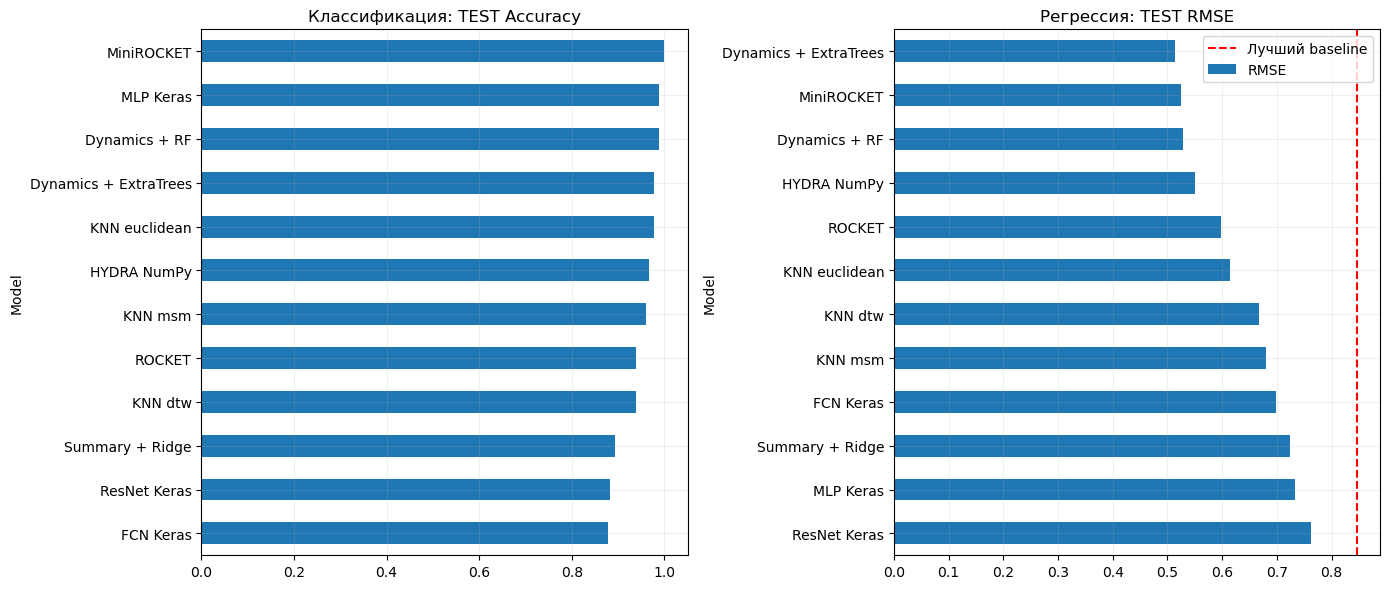

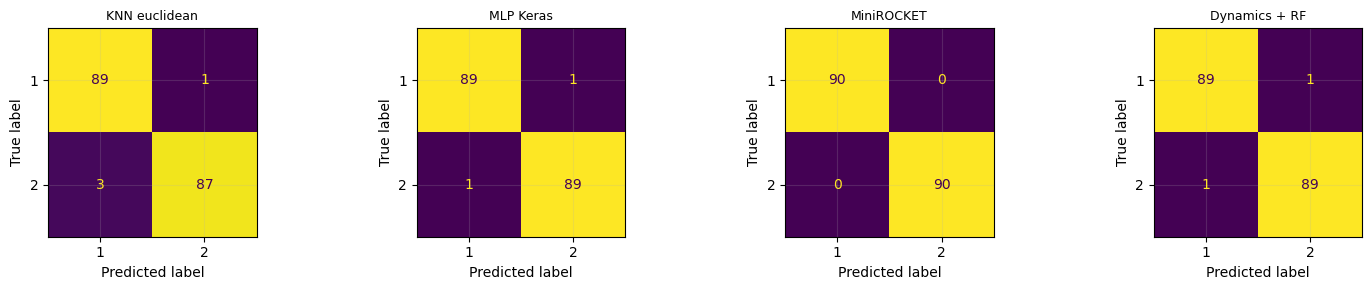

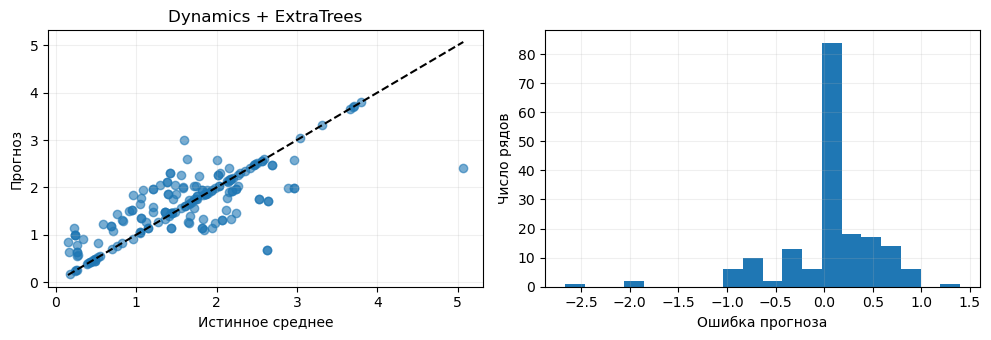

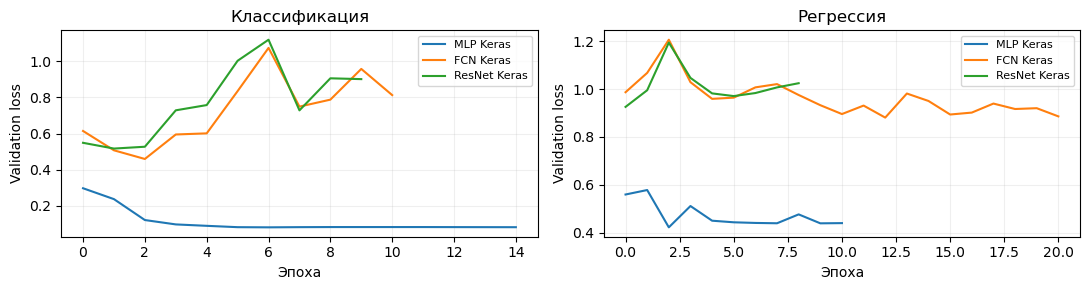

## Выводы

На TEST наибольшая Accuracy у MiniROCKET: 1.000, Macro F1 1.000

Минимальная RMSE у Dynamics + ExtraTrees: 0.5146, MAE 0.3188, R² 0.628, ошибка ниже лучшего baseline (0.8462)

Это описательное сравнение на 180 тестовых рядах, конфигурации и число эпох выбирались на отдельной части TRAIN

Случайные свертки учитывают локальную форму, а признаки уровня и последних входных измерений особенно полезны для прогноза среднего скрытого участка

Отсутствие полной z-нормализации проверено численно, но сведения о всей исходной обработке архива ограничены, дополнительные преобразования обучаются только на доступной части TRAIN

In [ ]:
results = pd.DataFrame(rows)
assert results.groupby(['Family','Task']).size().min() >= 3
classification = results[results.Task=='classification'].sort_values(['Accuracy','Macro F1'],ascending=False)
regression = results[results.Task=='regression'].sort_values('RMSE')
display(classification[['Family','Model','Library','Config','Accuracy','Macro F1','Validation score']].round(4))
display(regression[['Family','Model','Library','Config','MAE','RMSE','R2','Validation score']].round(4))
display(results.groupby(['Family','Task']).size().rename('Обучено моделей').to_frame())
fig, axes = plt.subplots(1,2,figsize=(14,6))
classification.set_index('Model')['Accuracy'].sort_values().plot.barh(ax=axes[0],xlim=(0,1.05),title='Классификация: TEST Accuracy')
regression.set_index('Model')['RMSE'].sort_values(ascending=False).plot.barh(ax=axes[1],title='Регрессия: TEST RMSE')
axes[1].axvline(baseline_table.RMSE.min(),color='red',linestyle='--',label='Лучший baseline')
axes[1].legend()
plt.tight_layout()
plt.show()
# Лучшие по validation, чтобы выбор графиков не превращался в подбор по TEST
selected = results[results.Task=='classification'].sort_values('Validation score',ascending=False).groupby('Family',sort=False).head(1)
fig, axes = plt.subplots(1,4,figsize=(15,3))
for ax, (_,row) in zip(axes,selected.iterrows()):
    ConfusionMatrixDisplay.from_predictions(y_test,predictions[('classification',row.Model)],ax=ax,colorbar=False)
    ax.set_title(row.Model,fontsize=9)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
best_reg_val = regression.sort_values('Validation score').iloc[0]
pred = predictions[('regression',best_reg_val.Model)]
axes[0].scatter(yr_test,pred,alpha=.6)
limits = [min(yr_test.min(),pred.min()),max(yr_test.max(),pred.max())]
axes[0].plot(limits,limits,'k--')
axes[0].set(xlabel='Истинное среднее',ylabel='Прогноз',title=best_reg_val.Model)
axes[1].hist(pred-yr_test,bins=20)
axes[1].set(xlabel='Ошибка прогноза',ylabel='Число рядов')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1,2,figsize=(11,3))
for (task,name),h in histories.items():
    ax = axes[0 if task=='classification' else 1]
    ax.plot(h['val_loss'],label=name)
for ax,title in zip(axes,['Классификация','Регрессия']):
    ax.set(title=title,xlabel='Эпоха',ylabel='Validation loss')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
out = ROOT/'outputs'/LAB_NAME
out.mkdir(parents=True,exist_ok=True)
results.to_csv(out/'metrics.csv',index=False)
pd.DataFrame(validation_rows).to_csv(out/'validation.csv',index=False)
baseline_table.to_csv(out/'baselines.csv',index=False)
import json, hashlib
split_spec = {'seed':SEED,'fit_indices':fit_idx.tolist(),'validation_indices':val_idx.tolist(),
    'regression_input':120,'regression_target':'mean_last_24',
    'train_sha256':hashlib.sha256((DATA/'PowerCons_TRAIN.txt').read_bytes()).hexdigest(),
    'test_sha256':hashlib.sha256((DATA/'PowerCons_TEST.txt').read_bytes()).hexdigest()}
(out/'split.json').write_text(json.dumps(split_spec,indent=2),encoding='utf-8')
np.savez_compressed(out/'predictions.npz',**{f'{task}__{name}':p for (task,name),p in predictions.items()})
best_c, best_r = classification.iloc[0],regression.iloc[0]
baseline_rmse = baseline_table.RMSE.min()
comparison = 'ниже' if best_r.RMSE < baseline_rmse else 'выше или равна'
display(Markdown(f"## Выводы\n\nНа TEST наибольшая Accuracy у {best_c.Model}: {best_c.Accuracy:.3f}, "
    f"Macro F1 {best_c['Macro F1']:.3f}\n\n"
    f"Минимальная RMSE у {best_r.Model}: {best_r.RMSE:.4f}, MAE {best_r.MAE:.4f}, R² {best_r.R2:.3f}, "
    f"ошибка {comparison} лучшего baseline ({baseline_rmse:.4f})\n\n"
    "Это описательное сравнение на 180 тестовых рядах, конфигурации и число эпох выбирались на отдельной части TRAIN\n\n"
    "Случайные свертки учитывают локальную форму, а признаки уровня и последних входных измерений особенно полезны для прогноза среднего скрытого участка\n\n"
    "Отсутствие полной z-нормализации проверено численно, но сведения о всей исходной обработке архива ограничены, дополнительные преобразования обучаются только на доступной части TRAIN"))